# AQI ANALYSIS OF INDIA USING PYTHON 
## DATA ANALYSIS AND VISUALIZATION PROJECT 
### TEAM MEMBER: ANKITA PATTNAYAK (250301370221), DISHA NITRAN SUNDI (250301370232)

Abstract

This project analyzes air quality data from different cities in India using Python. It studies AQI levels, major air pollutants, yearly trends, and differences between cities. Data cleaning, exploratory data analysis, and visualizations are used to understand air quality patterns. The project aims to present useful insights that can support better awareness of air pollution.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

file_path = r"C:\Users\disha\Desktop\AQI_Analysis_India\Dataset\city_day.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [4]:
print("Total cities:", df["City"].nunique())

print("\nAll cities in the dataset:")
print(sorted(df["City"].unique()))

Total cities: 26

All cities in the dataset:
['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64


In [6]:
print("Original dataset shape:", df.shape)

df_clean = df.dropna(subset=["AQI", "AQI_Bucket"]).copy()

print("Dataset shape after cleaning:", df_clean.shape)

print("Missing AQI values:", df_clean["AQI"].isnull().sum())

Original dataset shape: (29531, 16)
Dataset shape after cleaning: (24850, 16)
Missing AQI values: 0


In [7]:
print("Dataset Information:")
df_clean.info()

print("\nStatistical Summary:")
display(df_clean.describe())

Dataset Information:
<class 'pandas.DataFrame'>
Index: 24850 entries, 28 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        24850 non-null  str    
 1   Date        24850 non-null  str    
 2   PM2.5       24172 non-null  float64
 3   PM10        17764 non-null  float64
 4   NO          24463 non-null  float64
 5   NO2         24459 non-null  float64
 6   NOx         22993 non-null  float64
 7   NH3         18314 non-null  float64
 8   CO          24405 non-null  float64
 9   SO2         24245 non-null  float64
 10  O3          24043 non-null  float64
 11  Benzene     21315 non-null  float64
 12  Toluene     19024 non-null  float64
 13  Xylene      9478 non-null   float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.2 MB

Statistical Summary:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24172.000000,17764.000000,24463.000000,24459.000000,22993.000000,18314.000000,24405.000000,24245.000000,24043.000000,21315.000000,19024.000000,9478.000000,24850.000000
mean,67.476613,118.454435,17.622421,28.978391,32.289012,23.848366,2.345267,14.362933,34.912885,3.458668,9.525714,3.588683,166.463581
std,63.075398,89.487976,22.421138,24.627054,30.712855,25.875981,7.075208,17.428693,21.724525,16.036020,20.881085,6.754324,140.696585
min,0.040000,0.030000,0.030000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,29.000000,56.777500,5.660000,11.940000,13.110000,8.960000,0.590000,5.730000,19.250000,0.230000,1.027500,0.390000,81.000000
50%,48.785000,96.180000,9.910000,22.100000,23.680000,16.310000,0.930000,9.220000,31.250000,1.290000,3.575000,1.420000,118.000000
75%,80.925000,150.182500,20.030000,38.240000,40.170000,30.360000,1.480000,15.140000,46.080000,3.340000,10.180000,4.120000,208.000000
max,914.940000,917.080000,390.680000,362.210000,378.240000,352.890000,175.810000,186.080000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [8]:
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

print("Date conversion successful!")
print("Start date:", df_clean["Date"].min())
print("End date:", df_clean["Date"].max())

Date conversion successful!
Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00


In [9]:
city_aqi = df_clean.groupby("City")["AQI"].mean().sort_values(ascending=False)

print("Top 10 cities with highest average AQI:")
display(city_aqi.head(10).round(2))

Top 10 cities with highest average AQI:


City
Ahmedabad       452.12
Delhi           259.49
Patna           240.78
Gurugram        225.12
Lucknow         217.97
Talcher         172.89
Jorapokhar      159.25
Brajrajnagar    150.28
Kolkata         140.57
Guwahati        140.11
Name: AQI, dtype: float64

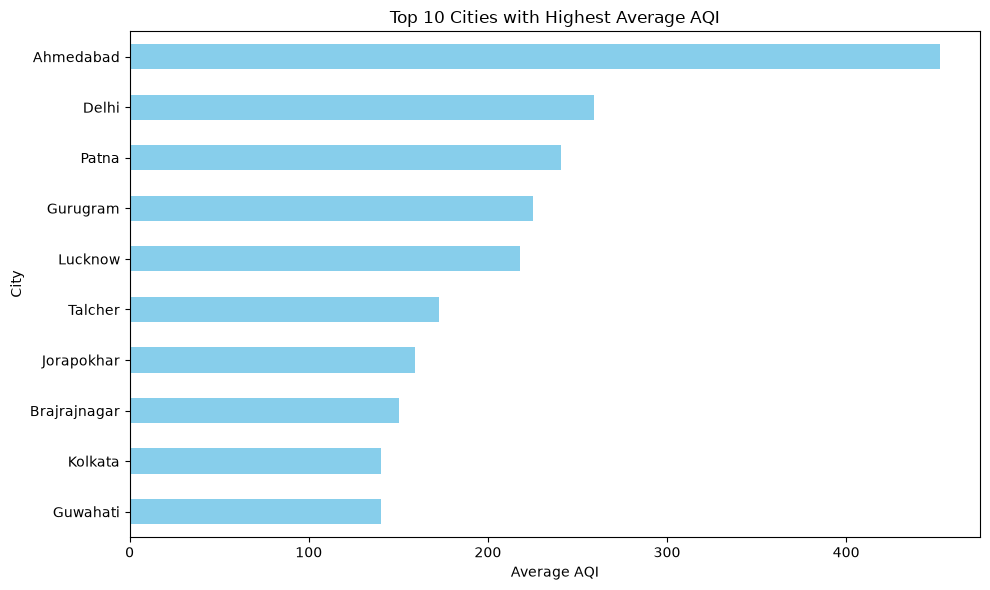

In [10]:
plt.figure(figsize=(10, 6))

city_aqi.head(10).sort_values().plot(
    kind="barh",
    color="skyblue"
)

plt.title("Top 10 Cities with Highest Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()

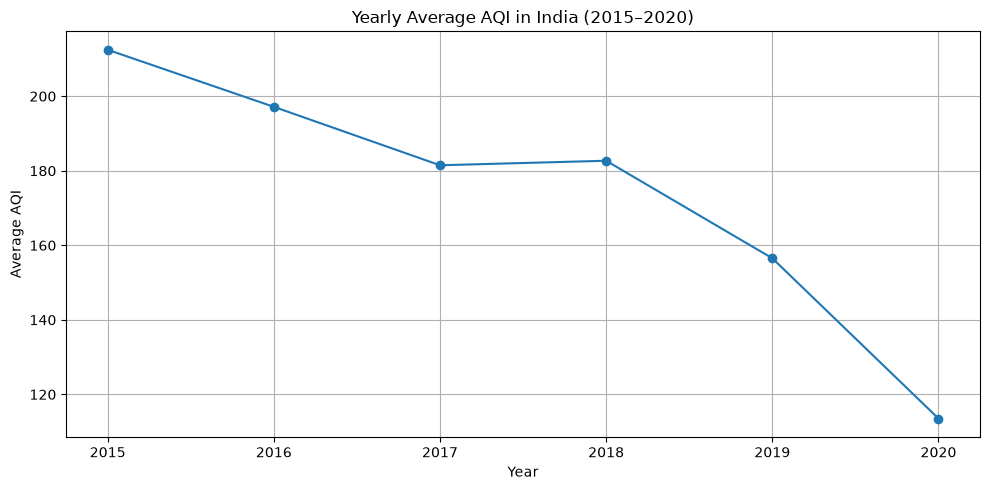

In [11]:
df_clean["Year"] = df_clean["Date"].dt.year

yearly_aqi = df_clean.groupby("Year")["AQI"].mean()

plt.figure(figsize=(10, 5))
plt.plot(yearly_aqi.index, yearly_aqi.values, marker="o")

plt.title("Yearly Average AQI in India (2015–2020)")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.xticks(yearly_aqi.index)
plt.grid(True)
plt.tight_layout()
plt.show()

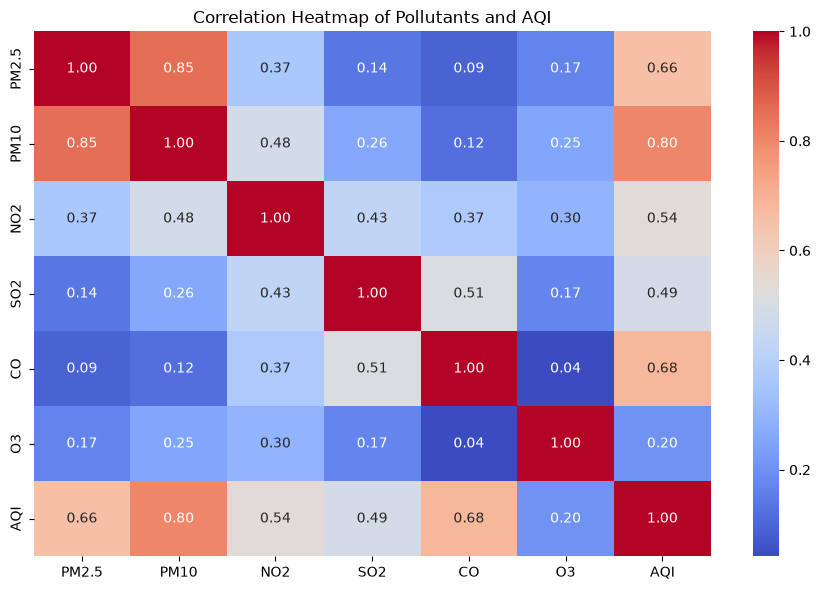

In [12]:
pollutants = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]

plt.figure(figsize=(9, 6))

sns.heatmap(
    df_clean[pollutants + ["AQI"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Pollutants and AQI")
plt.tight_layout()
plt.show()

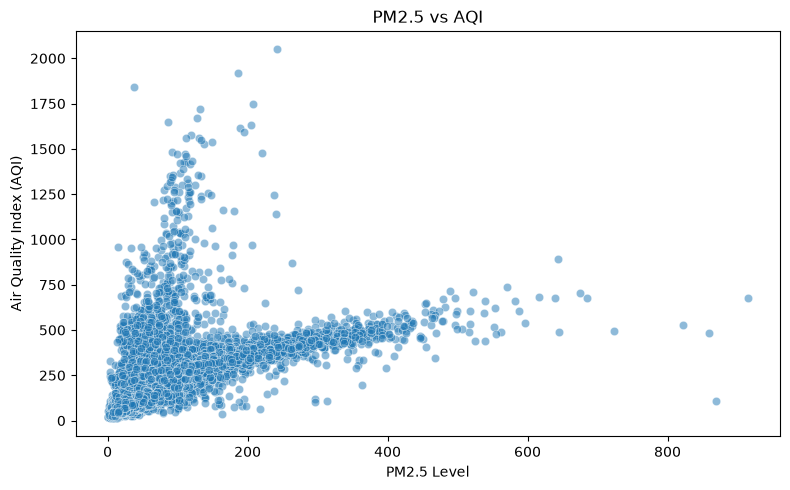

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="PM2.5",
    y="AQI",
    alpha=0.5
)

plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5 Level")
plt.ylabel("Air Quality Index (AQI)")
plt.tight_layout()
plt.show()

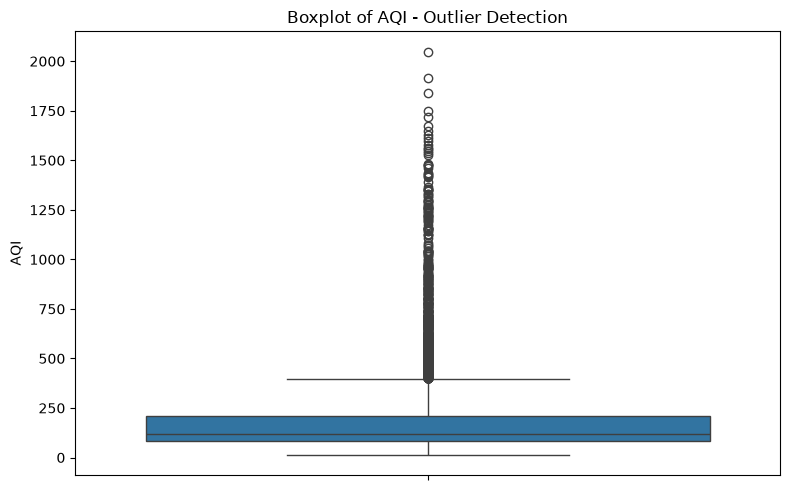

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, y="AQI")

plt.title("Boxplot of AQI - Outlier Detection")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

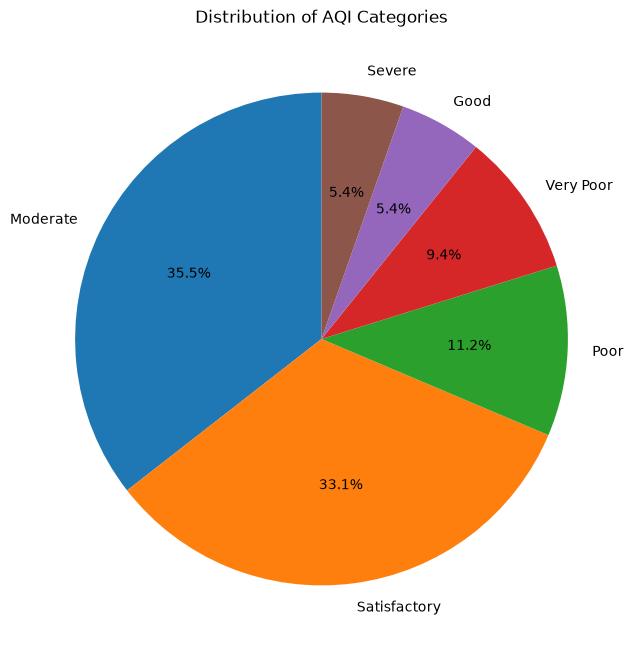

In [15]:
aqi_counts = df_clean["AQI_Bucket"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    aqi_counts,
    labels=aqi_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of AQI Categories")
plt.show()

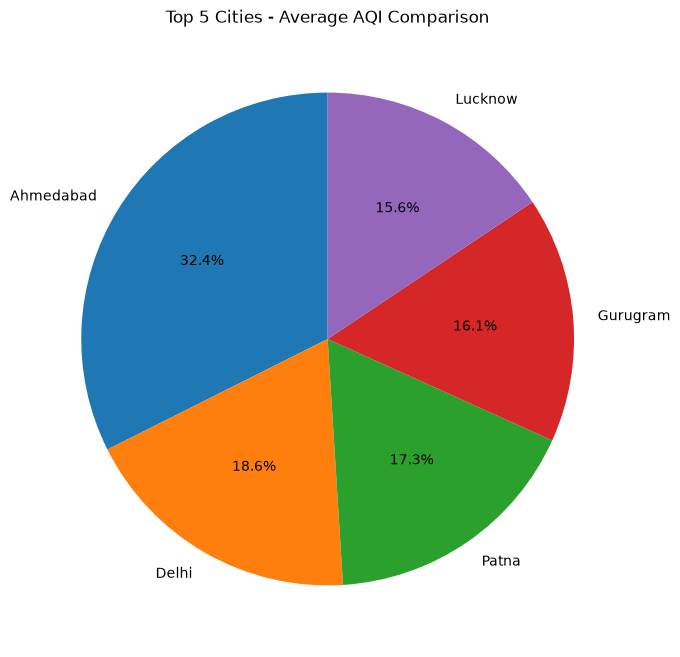

In [16]:
top5_cities = city_aqi.head(5)

plt.figure(figsize=(8, 8))

plt.pie(
    top5_cities.values,
    labels=top5_cities.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 Cities - Average AQI Comparison")
plt.show()

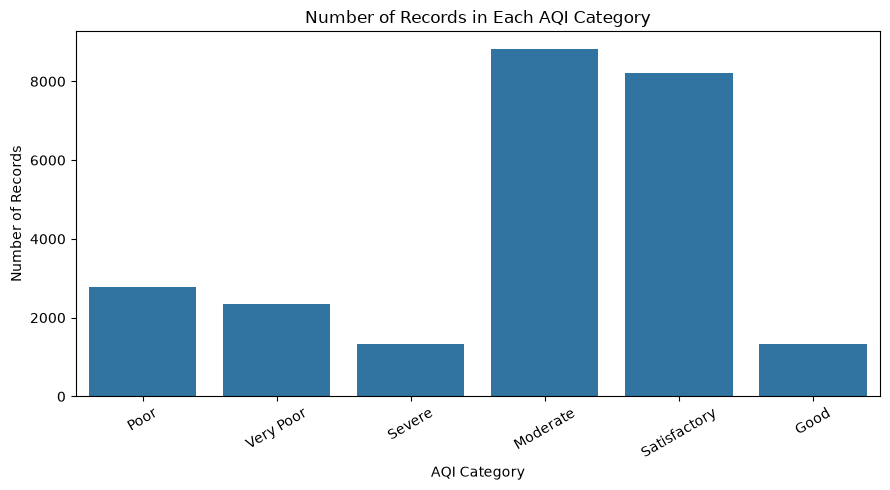

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df_clean, x="AQI_Bucket")

plt.title("Number of Records in Each AQI Category")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
Q1 = df_clean["AQI"].quantile(0.25)
Q3 = df_clean["AQI"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["AQI"] < lower_limit) |
    (df_clean["AQI"] > upper_limit)
]

print("Lower limit:", round(lower_limit, 2))
print("Upper limit:", round(upper_limit, 2))
print("Number of outliers:", len(outliers))

Lower limit: -109.5
Upper limit: 398.5
Number of outliers: 1358


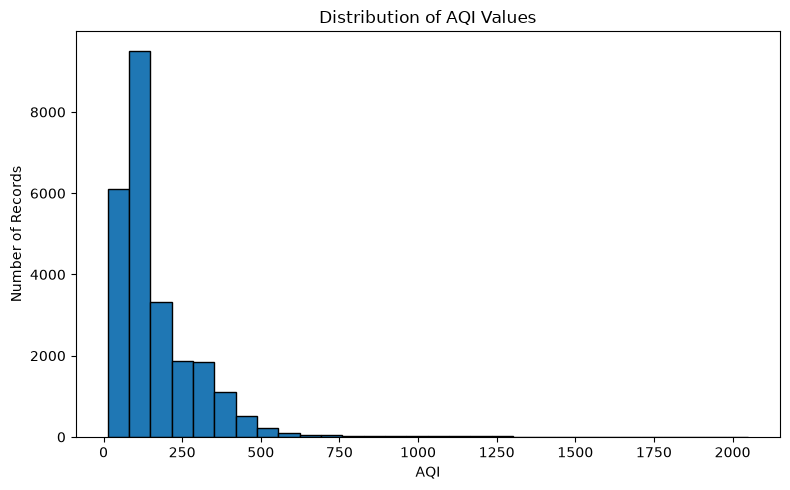

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean["AQI"], bins=30, edgecolor="black")

plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [20]:
pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene"
]

for col in pollutants:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

print("Missing pollutant values after cleaning:")
print(df_clean[pollutants].isnull().sum())

Missing pollutant values after cleaning:
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
dtype: int64


In [21]:
output_path = r"C:\Users\disha\Desktop\AQI_Analysis_India\Dataset\cleaned_aqi_data.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("Rows and columns:", df_clean.shape)

Cleaned dataset saved successfully!
Rows and columns: (24850, 17)


In [22]:
yearly_results = df_clean.groupby("Year")["AQI"].agg(
    ["mean", "min", "max"]
).round(2)

yearly_results.columns = [
    "Average AQI", "Minimum AQI", "Maximum AQI"
]

display(yearly_results)

,Average AQI,Minimum AQI,Maximum AQI
Year,,,
2015,212.46,31.0,1247.0
2016,197.15,20.0,1842.0
2017,181.47,26.0,1747.0
2018,182.68,13.0,2049.0
2019,156.52,14.0,1719.0
2020,113.52,14.0,1291.0


In [23]:
city_results = df_clean.groupby("City")["AQI"].agg(
    ["mean", "count"]
).round(2)

city_results.columns = ["Average AQI", "Number of Records"]

city_results = city_results.sort_values(
    by="Average AQI", ascending=False
)

display(city_results.head(10))

,Average AQI,Number of Records
City,,
Ahmedabad,452.12,1334
Delhi,259.49,1999
Patna,240.78,1459
Gurugram,225.12,1453
Lucknow,217.97,1893
Talcher,172.89,698
Jorapokhar,159.25,771
Brajrajnagar,150.28,713
Kolkata,140.57,754


In [24]:
pollutant_avg = df_clean[pollutants].mean().sort_values(
    ascending=False
)

display(pollutant_avg.round(2))

PM10       112.10
PM2.5       66.97
O3          34.79
NOx         31.65
NO2         28.87
NH3         21.87
NO          17.50
SO2         14.24
Toluene      8.13
Benzene      3.15
CO           2.32
Xylene       2.25
dtype: float64

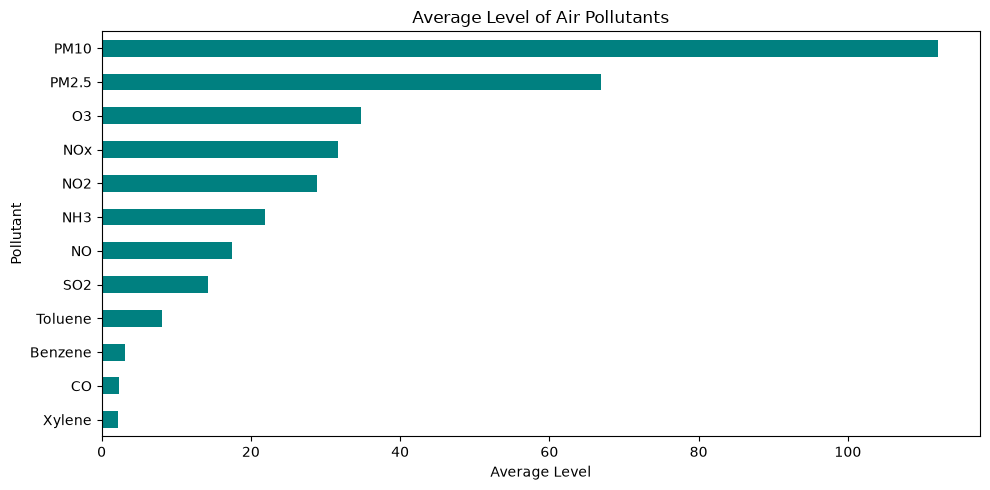

In [25]:
plt.figure(figsize=(10, 5))

pollutant_avg.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Average Level of Air Pollutants")
plt.xlabel("Average Level")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.show()

In [26]:
df.shape

(29531, 16)

In [27]:
df_clean.shape

(24850, 17)

 Findings and Conclusion

Key Findings

- Ahmedabad has the highest average AQI among the cities in our dataset.
- PM10 has the highest average concentration among the listed pollutants.
- The yearly average AQI generally decreased from 2015 to 2020.
- The dataset contains different AQI categories, from Good to Severe.

Conclusion

This project analyzes air quality across Indian cities using Python. Data cleaning and visualization help us understand pollution levels, compare cities, and observe yearly trends. The findings highlight the importance of monitoring air pollution and taking steps to improve air quality.

.....AI Integration – Policy Brief.....

In this section, we use Google Gemini AI to analyze the findings of our AQI project and suggest possible measures to reduce air pollution.

Policy Brief: Air Quality Analysis in India (2015–2020)
Executive Summary
This policy brief outlines the major insights gathered from our analysis of air quality data across selected Indian cities from 2015 to 2020. While our data shows an encouraging overall decrease in yearly average AQI over time, severe pollution levels remain a critical challenge.

1. Main Air Pollution Problems
High Overall AQI Levels: Cities like Ahmedabad, Delhi, Patna, and Gurugram experience extremely high average AQI levels, often falling into severe categories. Ahmedabad records the highest average AQI among the cities in the dataset.

Dominance of Particulate Matter: Particulate matter—specifically PM10 and PM2.5—shows the highest average concentrations among all listed pollutants, posing serious health risks.

Persistent Poor Air Quality: Despite improvements over the years (with national yearly averages declining from 2015 to 2020), many urban centers frequently exceed safe air quality limits.

2. Possible Causes
Vehicular Emissions: High traffic density, rising numbers of personal vehicles, and older engines contribute heavily to high carbon monoxide, nitrogen oxides, and particulate matter.

Industrial Activity & Construction: Industrial operations, factory emissions, and extensive urban construction generate large amounts of dust and pollutant gases (such as sulfur dioxide and nitrogen dioxide).

Dust and Road Resuspension: Unpaved roads, open soil, and construction debris easily get swept into the air as PM10 and PM2.5 particles, especially in drier weather.

3. Practical Recommendations to Reduce Air Pollution
Promote Electric and Public Transport: Expand public transportation networks and encourage the adoption of electric vehicles (EVs) to lower vehicle-related emissions.

Strict Industrial and Construction Regulations: Enforce tighter emission standards for factories and mandate dust-control measures at construction sites (such as covering materials and water sprinkling).

Enhance Urban Green Cover and Road Maintenance: Increase tree planting along major roads and pave unpaved surfaces to reduce dust resuspension and improve local air filtration.

4. Conclusion
While data from 2015 to 2020 shows a positive trend of decreasing yearly average AQI, air pollution in major Indian cities like Ahmedabad remains a pressing concern due to high particulate matter levels. Sustained monitoring, stricter local policies, and community-driven actions are essential to secure healthier air for everyone.

AI Tool Used:Google Gemini

Purposse:To generate a policy brief based on the findings of our AQI analysis.